In [27]:
# Cell 1: Imports

from pathlib import Path
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

In [28]:
# Cell 1: Imports, reproducibility, and publication-grade plotting

from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import tensorflow as tf

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# -----------------------------
# Publication-grade plotting style
# -----------------------------
mpl.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,

    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.8,
    "lines.markersize": 5,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": False,
    "legend.frameon": False,
    "image.cmap": "viridis",
})

# Colorblind-friendly palette
CB_COLORS = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # green
    "#CC79A7",  # purple
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#F0E442",  # yellow
    "#000000",  # black
]

print("TensorFlow version:", tf.__version__)
print("Setup complete with publication-grade plotting.")

TensorFlow version: 2.16.1
Setup complete with publication-grade plotting.


In [29]:
# Cell 1B: Save figures in manuscript-friendly formats

def save_figure(fig, out_dir, stem_name):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    png_path = out_dir / f"{stem_name}.png"
    pdf_path = out_dir / f"{stem_name}.pdf"

    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")

    print("Saved:")
    print(" -", png_path)
    print(" -", pdf_path)

In [30]:
# Cell 2: Rebuild cleaned file lists

PROJECT_ROOT = Path.cwd().resolve().parents[0] if "notebooks" in str(Path.cwd()) else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
CHBMIT_DIR = RAW_DIR / "chbmit"
TURKISH_DIR = RAW_DIR / "turkish"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
LOG_DIR = OUTPUT_DIR / "logs"

def is_windows_artifact(path: Path) -> bool:
    return "zone.identifier" in path.name.lower()

def list_real_files(root: Path):
    return sorted([p for p in root.rglob("*") if p.is_file() and not is_windows_artifact(p)])

chbmit_files_clean = list_real_files(CHBMIT_DIR)
turkish_files_clean = list_real_files(TURKISH_DIR)

print("CHB-MIT cleaned files:", len(chbmit_files_clean))
print("Turkish cleaned files:", len(turkish_files_clean))

CHB-MIT cleaned files: 857
Turkish cleaned files: 121


In [31]:
# Cell 2: Rebuild cleaned file lists

PROJECT_ROOT = Path.cwd().resolve().parents[0] if "notebooks" in str(Path.cwd()) else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
CHBMIT_DIR = RAW_DIR / "chbmit"
TURKISH_DIR = RAW_DIR / "turkish"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
LOG_DIR = OUTPUT_DIR / "logs"

def is_windows_artifact(path: Path) -> bool:
    return "zone.identifier" in path.name.lower()

def list_real_files(root: Path):
    return sorted([p for p in root.rglob("*") if p.is_file() and not is_windows_artifact(p)])

chbmit_files_clean = list_real_files(CHBMIT_DIR)
turkish_files_clean = list_real_files(TURKISH_DIR)

print("CHB-MIT cleaned files:", len(chbmit_files_clean))
print("Turkish cleaned files:", len(turkish_files_clean))

CHB-MIT cleaned files: 857
Turkish cleaned files: 121


In [32]:
# Cell 3: CHB-MIT recording-level metadata

chbmit_edf_files = sorted([p for p in chbmit_files_clean if p.suffix.lower() == ".edf"])
chbmit_seizure_files = sorted([p for p in chbmit_files_clean if p.suffix.lower() == ".seizures"])
chbmit_txt_files = sorted([p for p in chbmit_files_clean if p.suffix.lower() == ".txt"])

seizure_stems = set()
for f in chbmit_seizure_files:
    # Many CHB-MIT seizure files are named like chb01_03.edf.seizures or similar
    stem = f.name.replace(".seizures", "")
    seizure_stems.add(stem)
    seizure_stems.add(f.stem)

rows = []
for edf_path in chbmit_edf_files:
    subject_id = edf_path.parent.name.lower()
    recording_id = edf_path.stem
    
    has_seizure = (
        recording_id in seizure_stems or
        f"{recording_id}.edf" in seizure_stems
    )
    
    rows.append({
        "dataset": "CHB-MIT",
        "subject_id": subject_id,
        "recording_id": recording_id,
        "file_path": str(edf_path),
        "seizure_presence_recording": int(has_seizure)
    })

chbmit_recording_df = pd.DataFrame(rows)
chbmit_recording_df.head()

,dataset,subject_id,recording_id,file_path,seizure_presence_recording
0,CHB-MIT,chb01,chb01_01,/home/harman/projects/Sachin_Epilepsy_Revised/...,0
1,CHB-MIT,chb01,chb01_02,/home/harman/projects/Sachin_Epilepsy_Revised/...,0
2,CHB-MIT,chb01,chb01_03,/home/harman/projects/Sachin_Epilepsy_Revised/...,1
3,CHB-MIT,chb01,chb01_04,/home/harman/projects/Sachin_Epilepsy_Revised/...,1
4,CHB-MIT,chb01,chb01_05,/home/harman/projects/Sachin_Epilepsy_Revised/...,0


In [33]:
chbmit_recording_df.to_csv(TABLE_DIR / "chbmit_recording_metadata.csv", index=False)
print("Saved:", TABLE_DIR / "chbmit_recording_metadata.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/chbmit_recording_metadata.csv


In [34]:
# Cell 4: CHB-MIT subject-level metadata

chbmit_subject_meta = (
    chbmit_recording_df
    .groupby(["dataset", "subject_id"], as_index=False)
    .agg(
        n_recordings=("recording_id", "count"),
        n_seizure_recordings=("seizure_presence_recording", "sum")
    )
)

chbmit_subject_meta["seizure_presence_subject"] = (
    chbmit_subject_meta["n_seizure_recordings"] > 0
).astype(int)

chbmit_subject_meta["seizure_burden_ratio"] = (
    chbmit_subject_meta["n_seizure_recordings"] / chbmit_subject_meta["n_recordings"]
)

# Bin seizure burden for stratification
# Use duplicates='drop' to avoid failure if too few unique values
chbmit_subject_meta["burden_bin"] = pd.qcut(
    chbmit_subject_meta["seizure_burden_ratio"].rank(method="first"),
    q=min(3, chbmit_subject_meta.shape[0]),
    labels=False,
    duplicates="drop"
)

chbmit_subject_meta["burden_bin"] = chbmit_subject_meta["burden_bin"].fillna(0).astype(int)
chbmit_subject_meta["strata"] = (
    chbmit_subject_meta["seizure_presence_subject"].astype(str) + "_" +
    chbmit_subject_meta["burden_bin"].astype(str)
)

chbmit_subject_meta.head()

,dataset,subject_id,n_recordings,n_seizure_recordings,seizure_presence_subject,seizure_burden_ratio,burden_bin,strata
0,CHB-MIT,chb01,42,7,1,0.166667,1,1_1
1,CHB-MIT,chb02,36,3,1,0.083333,0,1_0
2,CHB-MIT,chb03,38,7,1,0.184211,1,1_1
3,CHB-MIT,chb04,42,3,1,0.071429,0,1_0
4,CHB-MIT,chb05,39,5,1,0.128205,0,1_0


In [35]:
chbmit_subject_meta.to_csv(TABLE_DIR / "chbmit_subject_metadata.csv", index=False)
print("Saved:", TABLE_DIR / "chbmit_subject_metadata.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/chbmit_subject_metadata.csv


In [36]:
# Cell 5: Turkish subject-level metadata

turkish_mat_files = sorted([p for p in turkish_files_clean if p.suffix.lower() == ".mat"])

rows = []
for mat_path in turkish_mat_files:
    class_label = mat_path.parent.name.lower()
    subject_id = mat_path.stem.lower()
    
    # You may update this mapping if your folders use different labels
    seizure_presence = 1 if "epile" in class_label else 0
    
    rows.append({
        "dataset": "Turkish",
        "subject_id": subject_id,
        "file_path": str(mat_path),
        "class_label": class_label,
        "n_recordings": 1,
        "n_seizure_recordings": seizure_presence,
        "seizure_presence_subject": seizure_presence,
        "seizure_burden_ratio": float(seizure_presence)
    })

turkish_subject_meta = pd.DataFrame(rows)

# Simple burden bin for Turkish
turkish_subject_meta["burden_bin"] = turkish_subject_meta["seizure_presence_subject"].astype(int)
turkish_subject_meta["strata"] = (
    turkish_subject_meta["seizure_presence_subject"].astype(str) + "_" +
    turkish_subject_meta["burden_bin"].astype(str)
)

turkish_subject_meta.head()

,dataset,subject_id,file_path,class_label,n_recordings,n_seizure_recordings,seizure_presence_subject,seizure_burden_ratio,burden_bin,strata
0,Turkish,1_epilepsy (1),/home/harman/projects/Sachin_Epilepsy_Revised/...,epilepsy,1,1,1,1.0,1,1_1
1,Turkish,1_epilepsy (10),/home/harman/projects/Sachin_Epilepsy_Revised/...,epilepsy,1,1,1,1.0,1,1_1
2,Turkish,1_epilepsy (11),/home/harman/projects/Sachin_Epilepsy_Revised/...,epilepsy,1,1,1,1.0,1,1_1
3,Turkish,1_epilepsy (12),/home/harman/projects/Sachin_Epilepsy_Revised/...,epilepsy,1,1,1,1.0,1,1_1
4,Turkish,1_epilepsy (13),/home/harman/projects/Sachin_Epilepsy_Revised/...,epilepsy,1,1,1,1.0,1,1_1


In [37]:
turkish_subject_meta.to_csv(TABLE_DIR / "turkish_subject_metadata.csv", index=False)
print("Saved:", TABLE_DIR / "turkish_subject_metadata.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/turkish_subject_metadata.csv


In [38]:
# Cell 6: Unified subject metadata

subject_meta_df = pd.concat(
    [chbmit_subject_meta, turkish_subject_meta],
    ignore_index=True
)

subject_meta_df.head()

,dataset,subject_id,n_recordings,n_seizure_recordings,seizure_presence_subject,seizure_burden_ratio,burden_bin,strata,file_path,class_label
0,CHB-MIT,chb01,42,7,1,0.166667,1,1_1,NaN,NaN
1,CHB-MIT,chb02,36,3,1,0.083333,0,1_0,NaN,NaN
2,CHB-MIT,chb03,38,7,1,0.184211,1,1_1,NaN,NaN
3,CHB-MIT,chb04,42,3,1,0.071429,0,1_0,NaN,NaN
4,CHB-MIT,chb05,39,5,1,0.128205,0,1_0,NaN,NaN


In [39]:
subject_meta_df.to_csv(TABLE_DIR / "subject_metadata_all.csv", index=False)
print("Saved:", TABLE_DIR / "subject_metadata_all.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/subject_metadata_all.csv


In [40]:
# Cell 7: Cohort summary before splitting

cohort_summary = (
    subject_meta_df
    .groupby("dataset", as_index=False)
    .agg(
        n_subjects=("subject_id", "nunique"),
        n_positive_subjects=("seizure_presence_subject", "sum"),
        mean_burden=("seizure_burden_ratio", "mean")
    )
)

cohort_summary

,dataset,n_subjects,n_positive_subjects,mean_burden
0,CHB-MIT,24,24,0.224439
1,Turkish,121,50,0.413223


In [41]:
cohort_summary.to_csv(TABLE_DIR / "cohort_summary.csv", index=False)
print("Saved:", TABLE_DIR / "cohort_summary.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/cohort_summary.csv


In [42]:
# Cell 8: Leakage-controlled outer subject-wise CV (dataset-aware version)

from sklearn.model_selection import KFold, StratifiedKFold, StratifiedShuffleSplit

N_OUTER_FOLDS = 10
VAL_RATIO = 0.20
RANDOM_STATE = 42

split_rows = []

for dataset_name in subject_meta_df["dataset"].unique():
    ds_df = subject_meta_df[subject_meta_df["dataset"] == dataset_name].reset_index(drop=True).copy()

    X = ds_df["subject_id"].values
    y_outer = ds_df["seizure_presence_subject"].values

    class_counts = pd.Series(y_outer).value_counts()
    n_unique_classes = len(class_counts)

    print(f"\nDataset: {dataset_name}")
    print(f"Total subjects: {len(ds_df)}")
    print("Outer class counts:")
    print(class_counts)

    # -----------------------------
    # Outer split logic
    # -----------------------------
    if n_unique_classes < 2:
        # Only one subject class present -> use plain KFold
        n_splits = min(N_OUTER_FOLDS, len(ds_df))
        print(f"Using KFold with {n_splits} folds (single-class subject cohort).")

        outer_splitter = KFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=RANDOM_STATE
        )
        outer_iterator = outer_splitter.split(X)

    else:
        min_class_count = class_counts.min()
        n_splits = min(N_OUTER_FOLDS, len(ds_df), min_class_count)
        print(f"Using StratifiedKFold with {n_splits} folds.")

        outer_splitter = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=RANDOM_STATE
        )
        outer_iterator = outer_splitter.split(X, y_outer)

    # -----------------------------
    # Outer loop
    # -----------------------------
    for fold_idx, (trainval_idx, test_idx) in enumerate(outer_iterator, start=1):
        trainval_df = ds_df.iloc[trainval_idx].reset_index(drop=True)
        test_df = ds_df.iloc[test_idx].reset_index(drop=True)

        tv_X = trainval_df["subject_id"].values
        y_inner_combined = trainval_df["strata"].values
        y_inner_presence = trainval_df["seizure_presence_subject"].values

        def safe_val_split(X_arr, y_arr, fallback_y_arr=None, val_ratio=0.20, seed=42):
            counts = pd.Series(y_arr).value_counts()
            min_count = counts.min()

            if len(counts) >= 2 and min_count >= 2:
                splitter = StratifiedShuffleSplit(
                    n_splits=1,
                    test_size=val_ratio,
                    random_state=seed
                )
                return next(splitter.split(X_arr, y_arr)), "combined_strata"

            if fallback_y_arr is not None:
                counts_fb = pd.Series(fallback_y_arr).value_counts()
                min_count_fb = counts_fb.min()

                if len(counts_fb) >= 2 and min_count_fb >= 2:
                    splitter = StratifiedShuffleSplit(
                        n_splits=1,
                        test_size=val_ratio,
                        random_state=seed
                    )
                    return next(splitter.split(X_arr, fallback_y_arr)), "seizure_presence"

            # Final fallback: random subject-level split
            n_samples = len(X_arr)
            n_val = max(1, int(round(val_ratio * n_samples)))
            rng = np.random.default_rng(seed)
            indices = np.arange(n_samples)
            rng.shuffle(indices)
            val_idx = indices[:n_val]
            train_idx = indices[n_val:]
            return (train_idx, val_idx), "random_fallback"

        (train_idx_inner, val_idx_inner), val_strategy = safe_val_split(
            tv_X,
            y_inner_combined,
            fallback_y_arr=y_inner_presence,
            val_ratio=VAL_RATIO,
            seed=RANDOM_STATE + fold_idx
        )

        train_df = trainval_df.iloc[train_idx_inner].reset_index(drop=True)
        val_df = trainval_df.iloc[val_idx_inner].reset_index(drop=True)

        # Save split manifest
        for _, row in train_df.iterrows():
            split_rows.append({
                "dataset": dataset_name,
                "outer_fold": fold_idx,
                "split": "train",
                "subject_id": row["subject_id"],
                "seizure_presence_subject": row["seizure_presence_subject"],
                "seizure_burden_ratio": row["seizure_burden_ratio"],
                "strata": row["strata"],
                "val_split_strategy": val_strategy
            })

        for _, row in val_df.iterrows():
            split_rows.append({
                "dataset": dataset_name,
                "outer_fold": fold_idx,
                "split": "val",
                "subject_id": row["subject_id"],
                "seizure_presence_subject": row["seizure_presence_subject"],
                "seizure_burden_ratio": row["seizure_burden_ratio"],
                "strata": row["strata"],
                "val_split_strategy": val_strategy
            })

        for _, row in test_df.iterrows():
            split_rows.append({
                "dataset": dataset_name,
                "outer_fold": fold_idx,
                "split": "test",
                "subject_id": row["subject_id"],
                "seizure_presence_subject": row["seizure_presence_subject"],
                "seizure_burden_ratio": row["seizure_burden_ratio"],
                "strata": row["strata"],
                "val_split_strategy": val_strategy
            })

split_manifest_df = pd.DataFrame(split_rows)
split_manifest_df.head()


Dataset: CHB-MIT
Total subjects: 24
Outer class counts:
1    24
Name: count, dtype: int64
Using KFold with 10 folds (single-class subject cohort).

Dataset: Turkish
Total subjects: 121
Outer class counts:
0    71
1    50
Name: count, dtype: int64
Using StratifiedKFold with 10 folds.


,dataset,outer_fold,split,subject_id,seizure_presence_subject,seizure_burden_ratio,strata,val_split_strategy
0,CHB-MIT,1,train,chb21,1,0.121212,1_0,combined_strata
1,CHB-MIT,1,train,chb10,1,0.280000,1_2,combined_strata
2,CHB-MIT,1,train,chb16,1,0.315789,1_2,combined_strata
3,CHB-MIT,1,train,chb03,1,0.184211,1_1,combined_strata
4,CHB-MIT,1,train,chb08,1,0.250000,1_1,combined_strata


In [43]:
# Diagnostic: inspect stratification group sizes

for dataset_name in subject_meta_df["dataset"].unique():
    ds_df = subject_meta_df[subject_meta_df["dataset"] == dataset_name].copy()

    print(f"\n=== {dataset_name} ===")
    print("Seizure presence counts:")
    print(ds_df["seizure_presence_subject"].value_counts(dropna=False))

    print("\nCombined strata counts:")
    print(ds_df["strata"].value_counts(dropna=False).sort_index())


=== CHB-MIT ===
Seizure presence counts:
seizure_presence_subject
1    24
Name: count, dtype: int64

Combined strata counts:
strata
1_0    8
1_1    8
1_2    8
Name: count, dtype: int64

=== Turkish ===
Seizure presence counts:
seizure_presence_subject
0    71
1    50
Name: count, dtype: int64

Combined strata counts:
strata
0_0    71
1_1    50
Name: count, dtype: int64


In [44]:
# Cell 9: Leakage safety checks

def check_split_leakage(split_df):
    problems = []
    
    for dataset_name in split_df["dataset"].unique():
        ds_df = split_df[split_df["dataset"] == dataset_name]
        
        for fold in sorted(ds_df["outer_fold"].unique()):
            fold_df = ds_df[ds_df["outer_fold"] == fold]
            
            train_subjects = set(fold_df[fold_df["split"] == "train"]["subject_id"])
            val_subjects = set(fold_df[fold_df["split"] == "val"]["subject_id"])
            test_subjects = set(fold_df[fold_df["split"] == "test"]["subject_id"])
            
            if train_subjects & val_subjects:
                problems.append((dataset_name, fold, "train-val overlap"))
            if train_subjects & test_subjects:
                problems.append((dataset_name, fold, "train-test overlap"))
            if val_subjects & test_subjects:
                problems.append((dataset_name, fold, "val-test overlap"))
    
    return problems

leakage_problems = check_split_leakage(split_manifest_df)

if len(leakage_problems) == 0:
    print("Leakage safety check passed: no subject overlap across train/val/test within any outer fold.")
else:
    print("Potential leakage problems found:")
    for p in leakage_problems:
        print(p)

Leakage safety check passed: no subject overlap across train/val/test within any outer fold.


In [45]:
# Cell 10: Split summary

split_summary_df = (
    split_manifest_df
    .groupby(["dataset", "outer_fold", "split"], as_index=False)
    .agg(
        n_subjects=("subject_id", "nunique"),
        n_positive_subjects=("seizure_presence_subject", "sum"),
        mean_burden=("seizure_burden_ratio", "mean")
    )
)

split_summary_df.head(20)

,dataset,outer_fold,split,n_subjects,n_positive_subjects,mean_burden
0,CHB-MIT,1,test,3,3,0.155806
1,CHB-MIT,1,train,16,16,0.235697
2,CHB-MIT,1,val,5,5,0.229596
3,CHB-MIT,2,test,3,3,0.307222
4,CHB-MIT,2,train,16,16,0.205185
5,CHB-MIT,2,val,5,5,0.236384
6,CHB-MIT,3,test,3,3,0.149779
7,CHB-MIT,3,train,16,16,0.233231
8,CHB-MIT,3,val,5,5,0.241102
9,CHB-MIT,4,test,3,3,0.271841


In [46]:
split_summary_df.to_csv(TABLE_DIR / "split_summary_by_fold.csv", index=False)
print("Saved:", TABLE_DIR / "split_summary_by_fold.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/split_summary_by_fold.csv


Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_split_distribution_chb-mit.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_split_distribution_chb-mit.pdf


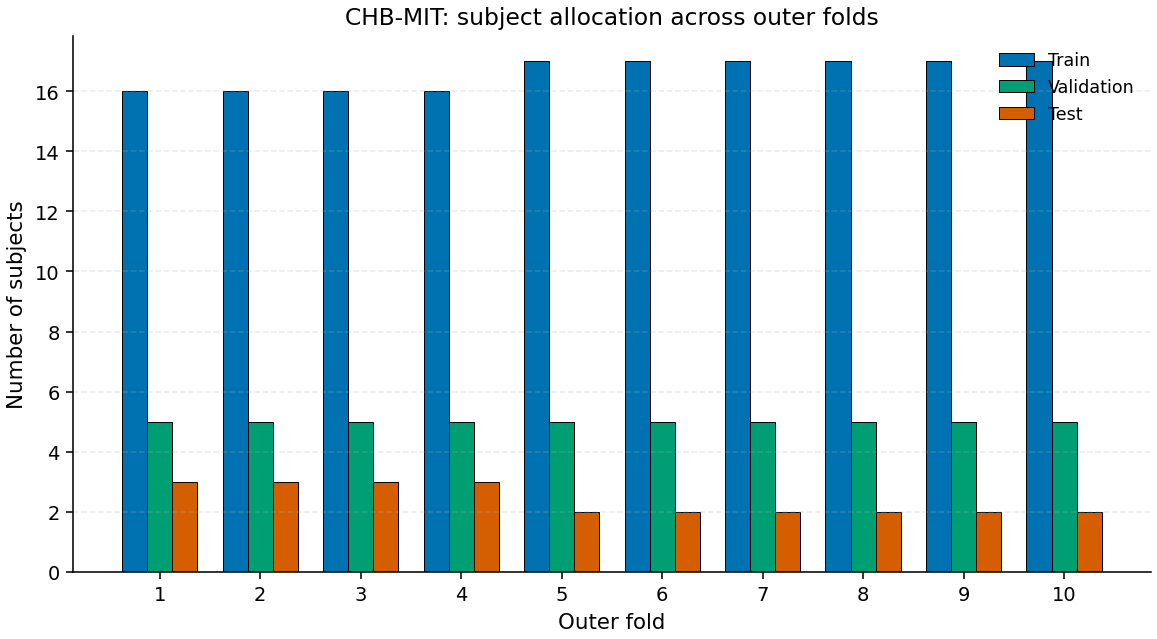

Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_split_distribution_turkish.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_split_distribution_turkish.pdf


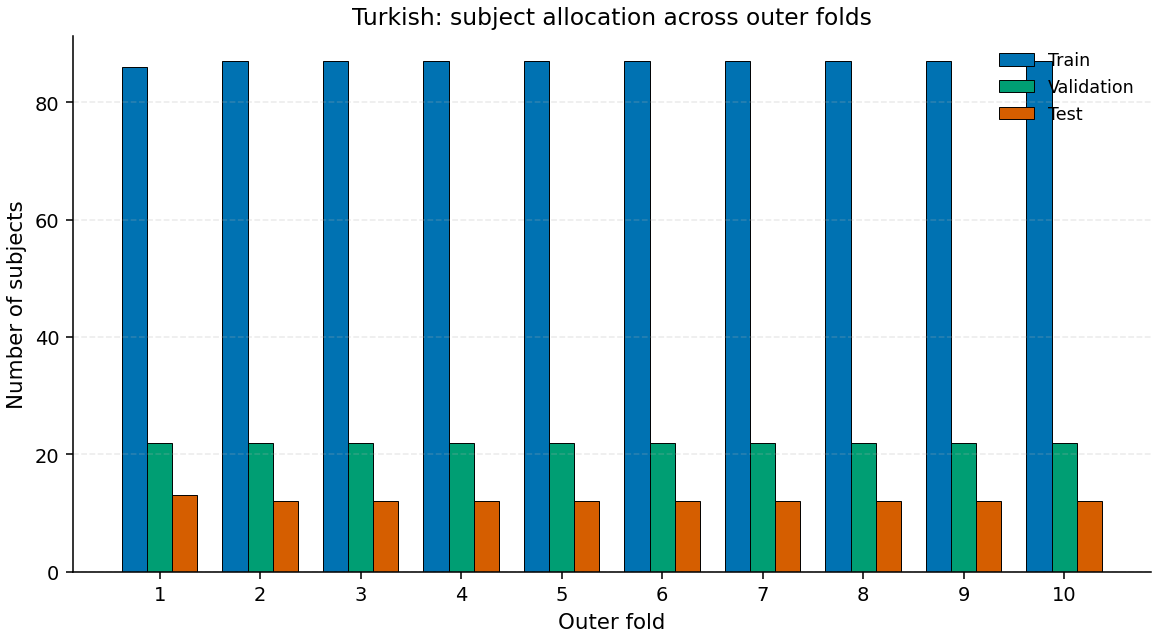

In [47]:
# Cell 11: Plot split composition across outer folds

for dataset_name in split_summary_df["dataset"].unique():
    ds_plot = split_summary_df[split_summary_df["dataset"] == dataset_name].copy()
    
    pivot_df = ds_plot.pivot(index="outer_fold", columns="split", values="n_subjects").fillna(0)
    pivot_df = pivot_df[["train", "val", "test"]]
    
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    
    x = np.arange(len(pivot_df.index))
    width = 0.25
    
    ax.bar(x - width, pivot_df["train"], width, label="Train", color=CB_COLORS[0], edgecolor="black", linewidth=0.5)
    ax.bar(x,         pivot_df["val"],   width, label="Validation", color=CB_COLORS[2], edgecolor="black", linewidth=0.5)
    ax.bar(x + width, pivot_df["test"],  width, label="Test", color=CB_COLORS[1], edgecolor="black", linewidth=0.5)
    
    ax.set_xlabel("Outer fold")
    ax.set_ylabel("Number of subjects")
    ax.set_title(f"{dataset_name}: subject allocation across outer folds")
    ax.set_xticks(x)
    ax.set_xticklabels(pivot_df.index)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    
    plt.tight_layout()
    save_figure(fig, FIG_DIR, f"fig_split_distribution_{dataset_name.lower()}")
    plt.show()

Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_positive_subject_distribution_chb-mit.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_positive_subject_distribution_chb-mit.pdf


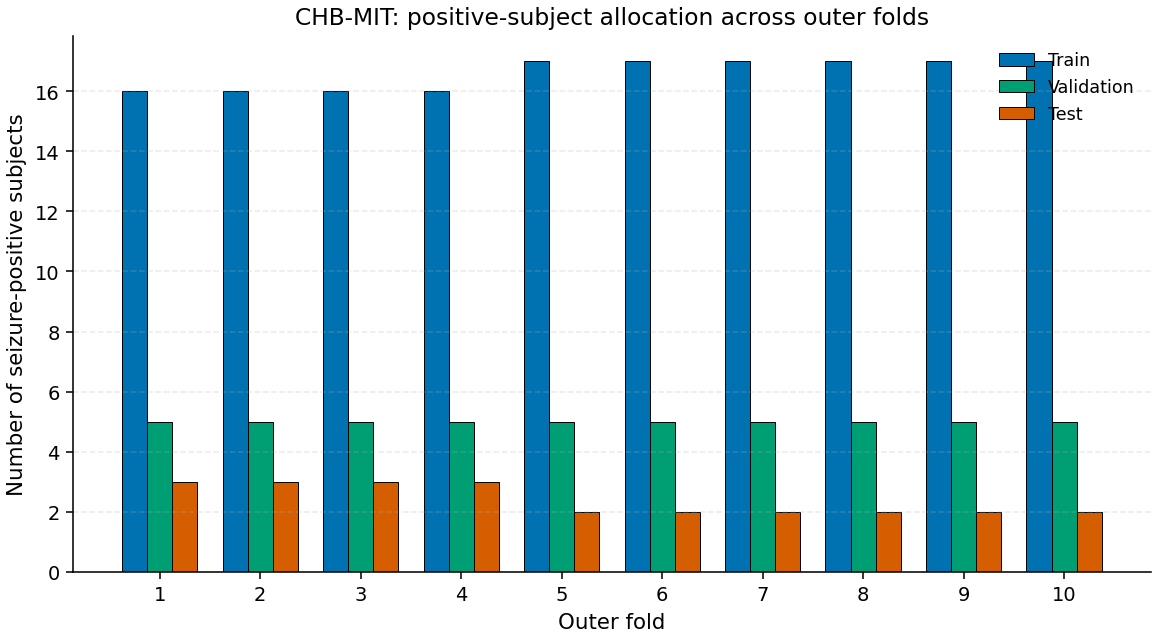

Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_positive_subject_distribution_turkish.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig_positive_subject_distribution_turkish.pdf


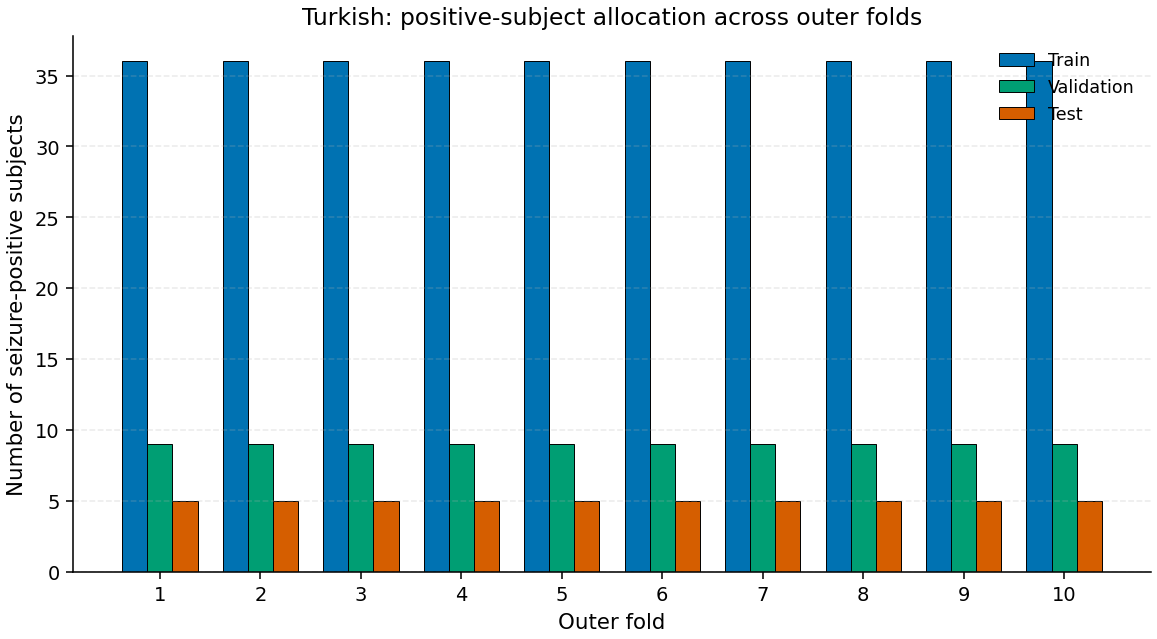

In [48]:
# Cell 12: Positive subject distribution across splits

for dataset_name in split_summary_df["dataset"].unique():
    ds_plot = split_summary_df[split_summary_df["dataset"] == dataset_name].copy()
    
    pivot_df = ds_plot.pivot(index="outer_fold", columns="split", values="n_positive_subjects").fillna(0)
    pivot_df = pivot_df[["train", "val", "test"]]
    
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    
    x = np.arange(len(pivot_df.index))
    width = 0.25
    
    ax.bar(x - width, pivot_df["train"], width, label="Train", color=CB_COLORS[0], edgecolor="black", linewidth=0.5)
    ax.bar(x,         pivot_df["val"],   width, label="Validation", color=CB_COLORS[2], edgecolor="black", linewidth=0.5)
    ax.bar(x + width, pivot_df["test"],  width, label="Test", color=CB_COLORS[1], edgecolor="black", linewidth=0.5)
    
    ax.set_xlabel("Outer fold")
    ax.set_ylabel("Number of seizure-positive subjects")
    ax.set_title(f"{dataset_name}: positive-subject allocation across outer folds")
    ax.set_xticks(x)
    ax.set_xticklabels(pivot_df.index)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    
    plt.tight_layout()
    save_figure(fig, FIG_DIR, f"fig_positive_subject_distribution_{dataset_name.lower()}")
    plt.show()